# GSB 5544 — Topic 8.2: Regression — SOLUTION
*Does advertising move sales? Fitting a line with scikit-learn, reading it with plotnine*

## The next 20 minutes

| | Question | New tools | |
|---|---|---|---|
| **1. The question and the data** | Which advertising channel moves sales, and by how much? | `read_csv`, `describe` | the business question comes first |
| **2. Summary statistics** | How big are the budgets, and which one *moves with* sales? | `.corr()` | one number per pair |
| **3. Visualisation** | What does the relationship look like? | `geom_point`, `geom_smooth(method="lm")` | a scatterplot before any model |
| **4. Analysis: simple linear regression** | What line best describes sales as a function of TV spend? | `LinearRegression().fit`, `.intercept_`, `.coef_`, `.predict`, `.score` | **predict** and **explain** |
| **5. Multiple linear regression** | What happens when we add a second feature? | the same four calls, two columns in `X` | coefficients that "hold the other constant" |

Every method so far in this course has answered *what is there*: counts, means, joins, nearest neighbours,
rules. **Regression** answers *how does one thing change with another* — and, once we have that, *what
would we expect if...*. Those two uses have names:

- **Predict**: given a new TV budget, what sales should we expect?
- **Explain**: for every extra \$1,000 of TV spend, how much do sales move?

Same model, two readings. Keep both in mind as we go.

In [1]:
import numpy as np
import pandas as pd
from plotnine import ggplot, aes, geom_point, geom_smooth, geom_abline, geom_hline, labs, theme_minimal
from sklearn.linear_model import LinearRegression

---
## 1. The question and the data

**The business question.** A company advertises a product in 200 different markets. In each market it
spends some budget on **TV**, **radio** and **newspaper** ads, and records the product's **sales**.
The marketing team wants to know: *which channel is worth the money, and what sales should we expect
from a given budget?*

**The data.** One row per market. The budgets are in thousands of dollars; `sales` is in thousands of
units. (This is the Advertising data set from *An Introduction to Statistical Learning*; it is read from
the book's website, and a copy sits in the course repository as `assignments/Data/advertising.csv`.)

In [2]:
ads = pd.read_csv("https://www.statlearning.com/s/Advertising.csv", index_col=0)
print(ads.shape)
ads.head()

(200, 4)


,TV,radio,newspaper,sales
1,230.1,37.8,69.2,22.1
2,44.5,39.3,45.1,10.4
3,17.2,45.9,69.3,9.3
4,151.5,41.3,58.5,18.5
5,180.8,10.8,58.4,12.9


✅ **Checkpoint 1.** What is the **observational unit** (what does one row represent)? Which column is the
**outcome** we want to predict or explain, and which columns are candidate **features** (explanatory
variables)? Are they quantitative or categorical?

**Answer:** One row is one **market** (200 of them). The outcome is **`sales`** (thousands of units). The candidate
features are **`TV`**, **`radio`** and **`newspaper`** — all three are **quantitative** (budgets in
thousands of dollars), which is what today's regression needs. Nothing here is categorical.

---
## 2. Summary statistics

Before any model: how big are the numbers, and which feature *moves with* sales?

In [3]:
ads.describe().round(2)

,TV,radio,newspaper,sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


A **correlation** is one number per pair of columns, between −1 and 1: how tightly the two move together
along a straight line. `.corr()` gives every pair at once.

In [4]:
ads.corr().round(3)

,TV,radio,newspaper,sales
TV,1.000,0.055,0.057,0.782
radio,0.055,1.000,0.354,0.576
newspaper,0.057,0.354,1.000,0.228
sales,0.782,0.576,0.228,1.000


✅ **Checkpoint 2.** (a) Which feature has the strongest correlation with `sales`? Which the weakest?
(b) `TV` and `radio` have a correlation of about 0.05. What does that tell you about how the company
*allocates* its budgets across the two channels? (c) The average TV budget is about \$147,000 and the
average sales figure is about 14,000 units. Can a correlation tell you *how many units* an extra
\$1,000 of TV buys? Why or why not?

**Answer:** (a) **TV** is strongest (0.78), then radio (0.58); **newspaper** is weakest (0.23). (b) Close to zero: markets
with big TV budgets are not systematically markets with big radio budgets — the two are allocated more or
less independently. That matters in section 5, because it means each channel's effect can be separated
cleanly. (c) **No.** Correlation is unit-free: it says how *tight* the straight-line relationship is, not how
*steep*. "Units of sales per \$1,000 of TV" is a slope, and a slope is what regression gives us.

---
## 3. Visualisation: look before you fit

Two quantitative variables → a **scatterplot** (Topic 2.1). Put the feature on *x* and the outcome on *y*:
the plot should read "as TV spend goes up, what happens to sales?"

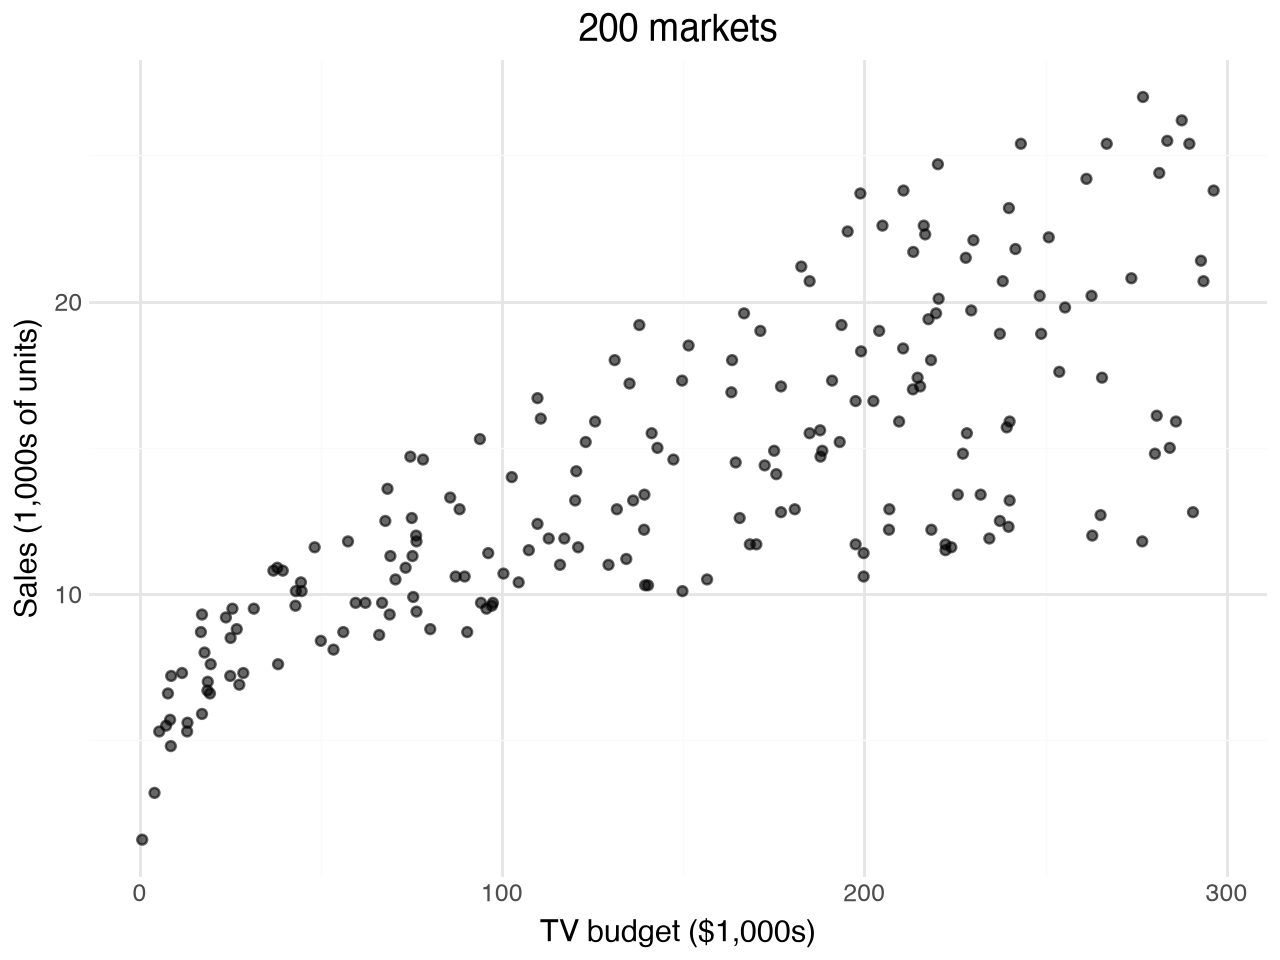

In [5]:
(ggplot(ads, aes(x="TV", y="sales"))
 + geom_point(alpha=0.6)
 + labs(x="TV budget ($1,000s)", y="Sales (1,000s of units)", title="200 markets")
 + theme_minimal())

`geom_smooth(method="lm")` draws the **least-squares line** (lm = linear model) through the cloud. It is a
preview of what we are about to compute by hand: plotnine fits the same line scikit-learn will.

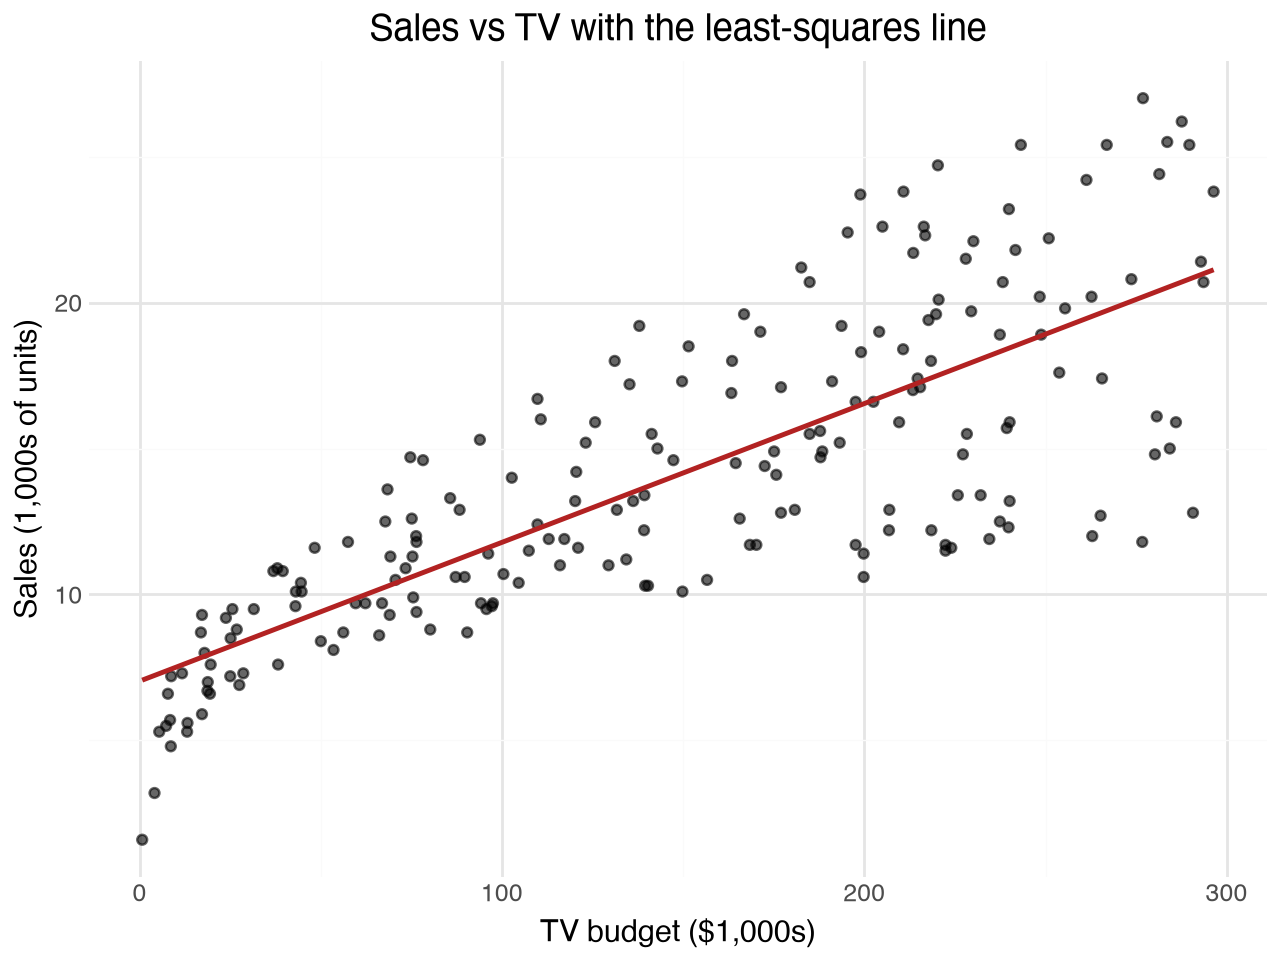

In [6]:
(ggplot(ads, aes(x="TV", y="sales"))
 + geom_point(alpha=0.6)
 + geom_smooth(method="lm", se=False, color="firebrick")
 + labs(x="TV budget ($1,000s)", y="Sales (1,000s of units)", title="Sales vs TV with the least-squares line")
 + theme_minimal())

✅ **Checkpoint 3.** (a) Describe the relationship in one sentence: direction, roughly linear or not,
tight or loose. (b) Look at the *spread* of the points around the line at TV ≈ 25 and at TV ≈ 275. Is it the
same? What would that mean for how confident you are in a prediction at each end?

**Answer:** (a) **Positive, roughly linear, moderately tight**: markets that spend more on TV sell more, and a straight
line is a reasonable summary, though the points scatter a few thousand units either side of it. (b) **No** —
the cloud is narrow at low TV budgets and fans out at high ones. A prediction for a \$25,000 market will
usually be closer to the truth than one for a \$275,000 market; the line is equally *unbiased* at both ends
but the *uncertainty* is larger on the right. (The textbook name for this is *heteroscedasticity*; today the
point is just to notice it.)

---
## 4. Analysis: simple linear regression

### The model

A straight line has two numbers: where it crosses the *y*-axis and how steep it is.

$$\text{sales} \approx \beta_0 + \beta_1 \cdot \text{TV}$$

**Least squares** picks the $\beta_0$ (intercept) and $\beta_1$ (slope) that make the vertical gaps
between the points and the line — the **residuals** — as small as possible in total (squared). That is all
`LinearRegression` does.

### The four calls

Every scikit-learn model follows the same pattern — learn it once, reuse it for every model in the rest of
the course:

| step | code | what it does |
|---|---|---|
| 1. choose | `model = LinearRegression()` | an empty model, nothing learned yet |
| 2. fit | `model.fit(X, y)` | find the best $\beta$s for features `X` and outcome `y` |
| 3. read | `model.intercept_`, `model.coef_` | the fitted numbers (the trailing `_` means "learned from data") |
| 4. use | `model.predict(X_new)`, `model.score(X, y)` | predictions for new rows; $R^2$ on the data |

**One rule to remember:** `X` must be **two-dimensional** — a DataFrame, even with one column — because
scikit-learn always thinks of features as a *table* with one column per feature. `y` is a Series.

In [7]:
X = ads[["TV"]]          # double brackets -> DataFrame (2-D), one feature column
y = ads["sales"]         # single brackets -> Series (1-D)
print(type(X).__name__, X.shape, "|", type(y).__name__, y.shape)

DataFrame (200, 1) | Series (200,)


In [8]:
model_tv = LinearRegression()
model_tv.fit(X, y)
print("intercept:", round(model_tv.intercept_, 4))
print("slope:    ", model_tv.coef_.round(4))

intercept: 7.0326
slope:     [0.0475]


Here is what happens when you forget the double brackets. The error message is long; the important words
are *2D array* and *reshape*.

In [9]:
LinearRegression().fit(ads["TV"], ads["sales"])     # 1-D feature -> error

ValueError: Expected a 2-dimensional container but got <class 'pandas.Series'> instead. Pass a DataFrame containing a single row (i.e. single sample) or a single column (i.e. single feature) instead.

### Explain: reading the two numbers

$$\widehat{\text{sales}} = 7.03 + 0.0475 \cdot \text{TV}$$

- **Slope 0.0475**: every extra **\$1,000** of TV budget is associated with about **0.0475 thousand = 47.5
  more units** sold, on average. (Or: \$1,000 of TV buys 47.5 units; \$21,000 buys about 1,000 units.)
- **Intercept 7.03**: a market with **zero** TV spend is predicted to sell about **7,030 units**. Here the
  intercept is meaningful because some markets really do spend close to nothing on TV (min 0.7). When
  *x* = 0 is far outside the data, the intercept is just where the line happens to cross and should not be
  read as a prediction.

### Predict: new budgets in, expected sales out

`predict` takes a table with the **same columns** as `X` and returns one prediction per row. Build the new
table with a dictionary so the column name matches.

In [10]:
new_markets = pd.DataFrame({"TV": [0, 100, 200, 300]})
new_markets["predicted_sales"] = model_tv.predict(new_markets[["TV"]])
new_markets

,TV,predicted_sales
0,0,7.032594
1,100,11.786258
2,200,16.539922
3,300,21.293586


✅ **Checkpoint 4.** (a) Check the prediction for TV = 100 by hand from the intercept and slope. (b) The
predictions go up by the same amount from 100 to 200 as from 200 to 300. Why must that be true for this
model? (c) The largest TV budget in the data is about \$296,000. Should you trust the prediction at
TV = 300? At TV = 1,000?

**Answer:** (a) 7.03 + 0.0475 × 100 = **11.79** thousand units — matches the table. (b) A straight line has one slope,
so every extra \$100,000 adds the same 4.75 thousand units no matter where you start. That is the model's
*assumption*, not a fact about advertising — real returns usually diminish. (c) TV = 300 is just beyond the
data, so the prediction is a mild **extrapolation** — plausible but unverified. TV = 1,000 is three times the
largest budget ever observed; the line will happily return 54.6 thousand units, but nothing in the data
supports that number. Predictions are only as good as the range of *x* the line was fitted on.

### How good is the line? Residuals and $R^2$

A **residual** is actual minus predicted: how far a market's real sales sit above (+) or below (−) the line.

In [11]:
ads["pred_tv"] = model_tv.predict(X)
ads["resid_tv"] = ads["sales"] - ads["pred_tv"]
ads[["TV", "sales", "pred_tv", "resid_tv"]].head().round(2)

,TV,sales,pred_tv,resid_tv
1,230.1,22.1,17.97,4.13
2,44.5,10.4,9.15,1.25
3,17.2,9.3,7.85,1.45
4,151.5,18.5,14.23,4.27
5,180.8,12.9,15.63,-2.73


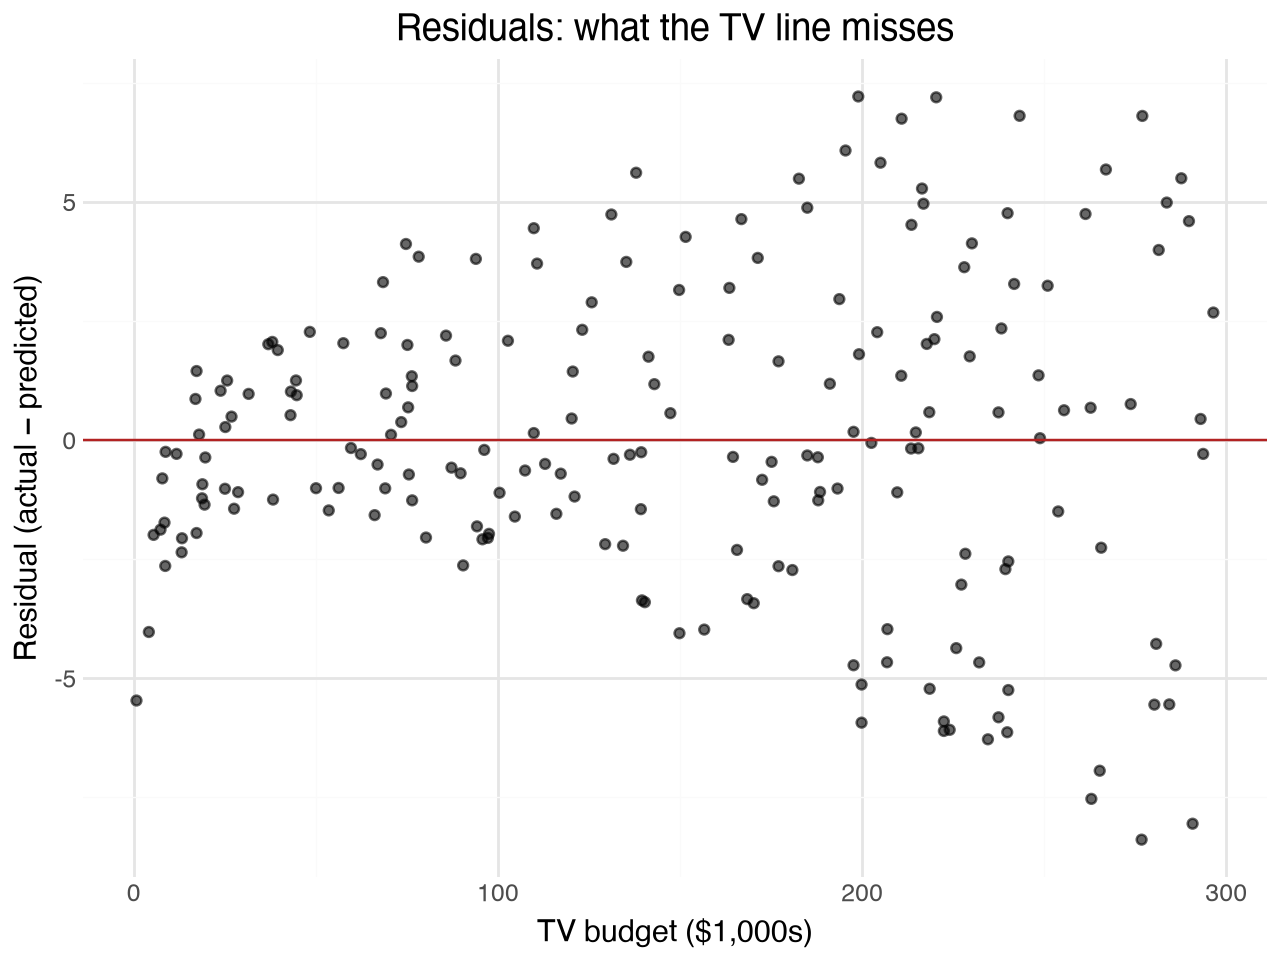

In [12]:
(ggplot(ads, aes(x="TV", y="resid_tv"))
 + geom_point(alpha=0.6)
 + geom_hline(yintercept=0, color="firebrick")
 + labs(x="TV budget ($1,000s)", y="Residual (actual − predicted)", title="Residuals: what the TV line misses")
 + theme_minimal())

`score(X, y)` returns **$R^2$**: the share of the variation in `sales` that the line accounts for, between 0
(the line explains nothing — you might as well predict the mean) and 1 (every point sits on the line).

In [13]:
r2_tv = model_tv.score(X, y)
rmse_tv = np.sqrt((ads["resid_tv"] ** 2).mean())
print(f"R² = {r2_tv:.3f}   typical miss (RMSE) = {rmse_tv:.2f} thousand units   (sd of sales = {ads['sales'].std():.2f})")

R² = 0.612   typical miss (RMSE) = 3.24 thousand units   (sd of sales = 5.22)


✅ **Checkpoint 5.** (a) In one sentence, what does $R^2 = 0.61$ say to the marketing team? (b) The typical
miss is about 3,200 units while sales average 14,000 — is this line useful? (c) What is left in the
residuals — pure noise, or something the model has not used yet? (Hint: there are two other columns.)

**Answer:** (a) "TV spend alone accounts for about **61%** of the market-to-market variation in sales; the other 39%
comes from things this line does not know about." (b) **Useful but rough**: a miss of ±3,200 on an
average of 14,000 is about ±23%. Good enough to rank markets, not good enough to set a budget to the
nearest thousand. (c) Some of the residual is noise, but some is **radio and newspaper**: a market that
also spends heavily on radio should sit *above* the TV line, and one that spends nothing *below* it. The
TV model lumps all of that into the residual. That is exactly what section 5 fixes.

---
## 5. Multiple linear regression: two quantitative features

### The model

Add a second slope:

$$\text{sales} \approx \beta_0 + \beta_1 \cdot \text{TV} + \beta_2 \cdot \text{radio}$$

In code the **only change** is that `X` has two columns. Same four calls.

In [14]:
X2 = ads[["TV", "radio"]]
model_tv_radio = LinearRegression().fit(X2, y)
print("intercept:", round(model_tv_radio.intercept_, 3))
print(pd.Series(model_tv_radio.coef_, index=X2.columns).round(4))

intercept: 2.921
TV       0.0458
radio    0.1880
dtype: float64


### Explain: a slope now means "holding the other feature fixed"

$$\widehat{\text{sales}} = 2.92 + 0.0458 \cdot \text{TV} + 0.188 \cdot \text{radio}$$

- **TV 0.0458**: among markets with the *same* radio budget, each extra \$1,000 of TV is associated with
  about 46 more units.
- **radio 0.188**: among markets with the *same* TV budget, each extra \$1,000 of radio is associated with
  about **188** more units — four times the TV effect per dollar.
- **Intercept 2.92**: predicted sales with no TV and no radio. Smaller than before (7.03) because the old
  intercept was quietly absorbing the average radio effect.

That phrase — *holding the other feature constant* — is what multiple regression adds. The TV slope barely
moved (0.0475 → 0.0458) because TV and radio budgets are nearly uncorrelated (Checkpoint 2b), so there was
little to disentangle.

### Predict: the new table needs both columns, in the same order

In [15]:
plan = pd.DataFrame({"TV": [100, 100, 200, 0], "radio": [20, 40, 0, 200]})
plan["predicted_sales"] = model_tv_radio.predict(plan[["TV", "radio"]])
plan.round(2)

,TV,radio,predicted_sales
0,100,20,11.26
1,100,40,15.02
2,200,0,12.07
3,0,200,40.52


In [16]:
r2_2 = model_tv_radio.score(X2, y)
ads["resid_tv_radio"] = y - model_tv_radio.predict(X2)
rmse_2 = np.sqrt((ads["resid_tv_radio"] ** 2).mean())
print(f"TV only:     R² = {r2_tv:.3f}   RMSE = {rmse_tv:.2f}")
print(f"TV + radio:  R² = {r2_2:.3f}   RMSE = {rmse_2:.2f}")

TV only:     R² = 0.612   RMSE = 3.24
TV + radio:  R² = 0.897   RMSE = 1.67


✅ **Checkpoint 6.** (a) Rows 1 and 2 of `plan` have the same TV budget and differ by \$20,000 of radio.
Check the difference in predicted sales by hand from the radio slope. (b) Row 3 (all TV) and row 4 (all
radio) spend the same \$200,000. The model prefers radio by a mile — should the company move its entire
budget to radio? Name one reason to be careful. (c) $R^2$ went from 0.61 to 0.90 and the typical miss
halved. In plain words, what did adding radio buy us?

**Answer:** (a) 0.188 × 20 = **3.76** thousand units: 11.26 → 15.02 in the table. (b) **Not on this evidence alone.**
The data contain no market that spends \$200,000 on radio (the maximum is about \$50,000), so row 4 is a
wild **extrapolation** — the line is straight, reality probably is not (radio audiences saturate). And this
is observational data: markets *chose* their budgets, so the slope is an association, not a guaranteed
return on a budget *we* set. A sensible reading is "radio looks under-used relative to TV; test a modest
shift." (c) About **29 percentage points** of the variation that the TV line called "noise" was really the
radio budget. Knowing both budgets lets us predict a market's sales to within about ±1,700 units instead
of ±3,200 — a prediction the team could plan around.

### What about newspaper?

Add the third feature the same way and look at its slope.

In [17]:
X3 = ads[["TV", "radio", "newspaper"]]
model_all = LinearRegression().fit(X3, y)
print(pd.Series(model_all.coef_, index=X3.columns).round(4))
print(f"R² = {model_all.score(X3, y):.3f}")

TV           0.0458
radio        0.1885
newspaper   -0.0010
dtype: float64
R² = 0.897


✅ **Checkpoint 7.** Newspaper's correlation with sales was 0.23 (Checkpoint 2), yet its slope *holding TV
and radio fixed* is about zero and $R^2$ does not move. How can both be true? (Hint: newspaper and radio
have correlation 0.35.)

**Answer:** Newspaper spend tends to travel **with radio spend** (correlation 0.35). On its own, newspaper looks mildly
related to sales only because the markets that buy newspaper ads also buy radio ads, and *radio* sells. Once
radio is in the model, newspaper has nothing left to explain: its slope (−0.001) is zero for practical
purposes and $R^2$ stays at 0.897. The lesson: a feature's slope in a multiple regression is its effect
**after** the other features have had their say, which can be very different from its correlation alone.

---
## Predict vs explain: the same line, two jobs

| | Predict | Explain |
|---|---|---|
| **Question** | What sales should we expect for *this* budget? | How much does sales move per \$1,000 of *this* channel? |
| **Looks at** | `model.predict(new_X)` | `model.coef_` (and `intercept_`) |
| **Judged by** | $R^2$, typical miss (RMSE), honest range of *x* | sign, size and units of each slope; what is held constant |
| **Main danger** | extrapolating beyond the data | reading an association as a cause |

## The lines to keep

| | |
|---|---|
| **Before the model** | `ads.corr()` for *which* features; a scatterplot with `geom_smooth(method="lm")` for *what shape* |
| **Fit** | `model = LinearRegression().fit(X, y)` — `X` is a DataFrame (double brackets), `y` a Series |
| **Explain** | `model.intercept_`, `model.coef_` — "per one-unit increase in *x*, holding the others fixed" |
| **Predict** | `model.predict(new_df[same_columns])`; `model.score(X, y)` is $R^2$; residual = actual − predicted |
| **Add a feature** | one more column in `X`; everything else is identical |

Course site: [https://gato365.github.io/gsb5544_instructor_learn_prep/](https://gato365.github.io/gsb5544_instructor_learn_prep/).